# Task 2 — Real Estate Housing Price Prediction (OLS vs Ridge vs Lasso)

**Goal:** Predict `median_house_value` on the California Housing dataset, and compare **OLS**, **Ridge (L2)** and **Lasso (L1)** regression using **RMSE, MAE and R²**.

**Tools:** Python, pandas, NumPy, scikit-learn, seaborn, matplotlib

---
## Project components

| # | Section | What it covers |
|---|---|---|
| 0 | Setup | Install and import libraries, set random seed |
| 1 | Load & explore data | Load CSV, structure, summary statistics, missing values, target distribution |
| 2 | Train / test split | 80/20 split *before* any preprocessing (prevents data leakage) |
| 3 | Feature engineering | Ratio and interaction features, median imputation, outlier clipping |
| 4 | Correlation & multicollinearity | Correlation heatmap, Variance Inflation Factor (VIF) |
| 5 | Preprocessing pipeline | StandardScaler for numeric, One-Hot encoding for `ocean_proximity` |
| 6 | Model training | OLS, Ridge and Lasso with `GridSearchCV` over `alpha` |
| 7 | Evaluation | RMSE, MAE, R² on the held-out test set |
| 8 | Predicted vs actual | Scatter plots for each model |
| 9 | Residual analysis | Residual distributions and residuals vs predicted |
| 10 | Coefficient analysis | OLS vs Ridge vs Lasso coefficients, Lasso regularisation path |
| 11 | Conclusion | Final comparison and summary |

## Requirement checklist

| Requirement from the task | Where |
|---|---|
| Load California Housing dataset | Section 1 |
| Impute null values | Section 3 (`total_bedrooms`, median) |
| Correlation heatmaps | Section 4.1 |
| Engineer interaction features | Section 3 |
| Handle multicollinearity | Sections 4 and 6 (VIF, mean-centering, Ridge/Lasso) |
| Standardise continuous variables, encode categoricals | Section 5 |
| Fit Ridge and Lasso over multiple alphas with `GridSearchCV` | Section 6 |
| Compare OLS, Ridge, Lasso on RMSE, MAE, R² | Section 7 |
| Plot predicted vs actual and residual distributions | Sections 8 and 9 |

### 0.2 Import libraries and set configuration

In [20]:
%pip install seaborn
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

## 1. Load the data
The file is the standard California Housing CSV (1990 census block groups). Update `DATA_PATH` if your starter file lives elsewhere.

### 1.1 Load the dataset

In [21]:
DATA_PATH = "housing.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### 1.2 Dataset structure and data types

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.5 MB


### 1.3 Summary statistics

In [23]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


### 1.4 Missing values, capped target and category counts

In [24]:
missing = df.isna().sum()
print(missing[missing > 0], "\n")
print("Rows capped at 500001:", (df["median_house_value"] >= 500001).sum(),
      f"({(df['median_house_value'] >= 500001).mean():.1%})")
print()
print(df["ocean_proximity"].value_counts())

total_bedrooms    207
dtype: int64 

Rows capped at 500001: 965 (4.7%)

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


### 1.5 Target distribution and geographic view

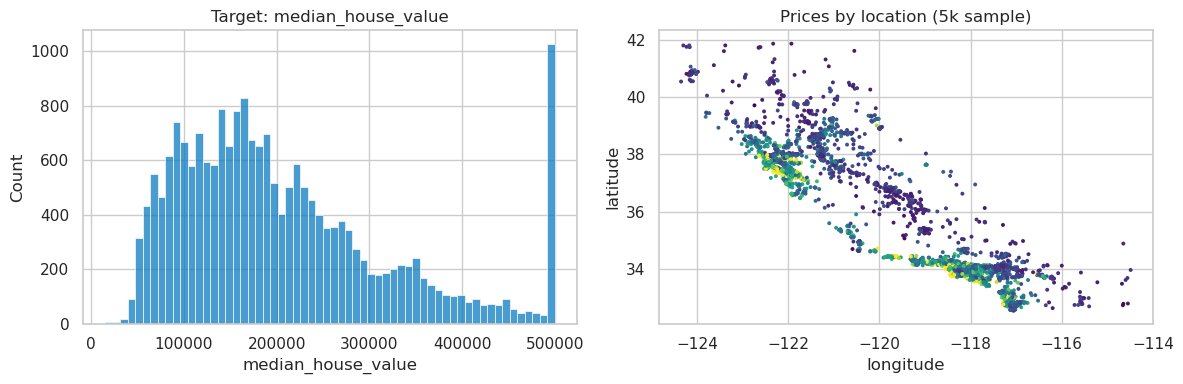

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["median_house_value"], bins=60, ax=axes[0], color="#0b7bc1")
axes[0].set_title("Target: median_house_value")
sns.scatterplot(data=df.sample(5000, random_state=1), x="longitude", y="latitude",
                hue="median_house_value", palette="viridis", s=8, linewidth=0, ax=axes[1], legend=False)
axes[1].set_title("Prices by location (5k sample)")
plt.tight_layout(); plt.show()

## 2. Train / test split first (avoid data leakage)
Imputation medians, scaling statistics and `alpha` selection must be learned **only from training data**. So we split now and put all preprocessing inside a scikit-learn `Pipeline`; the test set is touched once, at the very end.

### 2.1 Create the train / test split

In [26]:
TARGET = "median_house_value"
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

(16512, 9) (4128, 9)


## 3. Feature engineering (interaction & ratio features)
Raw counts like `total_rooms` depend on how big a block group is, so ratios are far more informative. We also add interaction terms so a *linear* model can capture combined effects.

| Feature | Idea |
|---|---|
| `rooms_per_household` | typical house size |
| `bedrooms_per_room` | share of rooms that are bedrooms (lower ≈ more upscale) |
| `population_per_household` | crowding |
| `income_x_rooms` | income × house size |
| `income_x_age` | income × building age |
| `lat_x_lon` | simple geographic interaction |
| `income_sq` | non-linear income effect |

`total_bedrooms` is imputed first (median of the training set), then the features are derived. The three ratios are **winsorised at the 0.5/99.5 percentiles** (of the training set) because a block group with very few households produces absurd ratios that would otherwise dominate a linear fit. Everything is implemented as a transformer so it runs inside the pipeline.

### 3.1 Feature engineering transformer (imputation, ratios, interactions)

In [27]:
from sklearn.base import BaseEstimator, TransformerMixin

class HousingFeatureEngineer(BaseEstimator, TransformerMixin):
    """Median-imputes total_bedrooms, adds ratio/interaction features and winsorises the ratios.
    Interactions use MEAN-CENTERED inputs (means learned on train only), which removes most of the
    structural collinearity between a product/square and its parent columns."""
    def fit(self, X, y=None):
        self.bedroom_median_ = X["total_bedrooms"].median()
        self.means_ = {c: X[c].mean() for c in ["median_income", "housing_median_age", "latitude", "longitude"]}
        rph = X["total_rooms"] / X["households"]
        # clip limits for ratio features (extreme values arise when 'households' is tiny)
        bpr = X["total_bedrooms"].fillna(self.bedroom_median_) / X["total_rooms"]
        pph = X["population"] / X["households"]
        self.clip_ = {"rooms_per_household": rph.quantile([.005, .995]).values,
                      "bedrooms_per_room": bpr.quantile([.005, .995]).values,
                      "population_per_household": pph.quantile([.005, .995]).values}
        self.means_["rooms_per_household"] = rph.clip(*self.clip_["rooms_per_household"]).mean()
        return self

    def transform(self, X):
        X = X.copy()
        X["total_bedrooms"] = X["total_bedrooms"].fillna(self.bedroom_median_)

        X["rooms_per_household"]      = X["total_rooms"] / X["households"]
        X["bedrooms_per_room"]        = X["total_bedrooms"] / X["total_rooms"]
        X["population_per_household"] = X["population"] / X["households"]
        for col, (lo, hi) in self.clip_.items():                  # winsorise ratios (train quantiles)
            X[col] = X[col].clip(lo, hi)

        c = {k: X[k] - m for k, m in self.means_.items()}          # centered copies
        X["income_x_rooms"] = c["median_income"] * c["rooms_per_household"]
        X["income_x_age"]   = c["median_income"] * c["housing_median_age"]
        X["lat_x_lon"]      = c["latitude"] * c["longitude"]
        X["income_sq"]      = c["median_income"] ** 2
        return X

fe = HousingFeatureEngineer().fit(X_train)
X_train_fe = fe.transform(X_train)
print("Imputed total_bedrooms median:", fe.bedroom_median_)
print("Nulls left in train:", int(X_train_fe.isna().sum().sum()))
X_train_fe.head()

Imputed total_bedrooms median: 437.0
Nulls left in train: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms,income_x_age,lat_x_lon,income_sq
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,NEAR OCEAN,5.017657,0.200576,3.691814,0.221767,-2.727933,-7.486249,0.385833
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,NEAR OCEAN,4.473545,0.232703,1.738095,0.061506,-1.391821,-2.664162,0.004659
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,NEAR OCEAN,5.645833,0.174486,2.723214,0.074715,-6.780708,0.882582,0.075925
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,NEAR OCEAN,4.002817,0.258269,3.994366,2.659021,-14.327023,-7.301043,3.756830
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,INLAND,6.268421,0.180940,2.300000,-0.291855,-4.699676,-0.247503,0.106638


## 4. Correlation heatmap & multicollinearity

### 4.1 Correlation heatmap

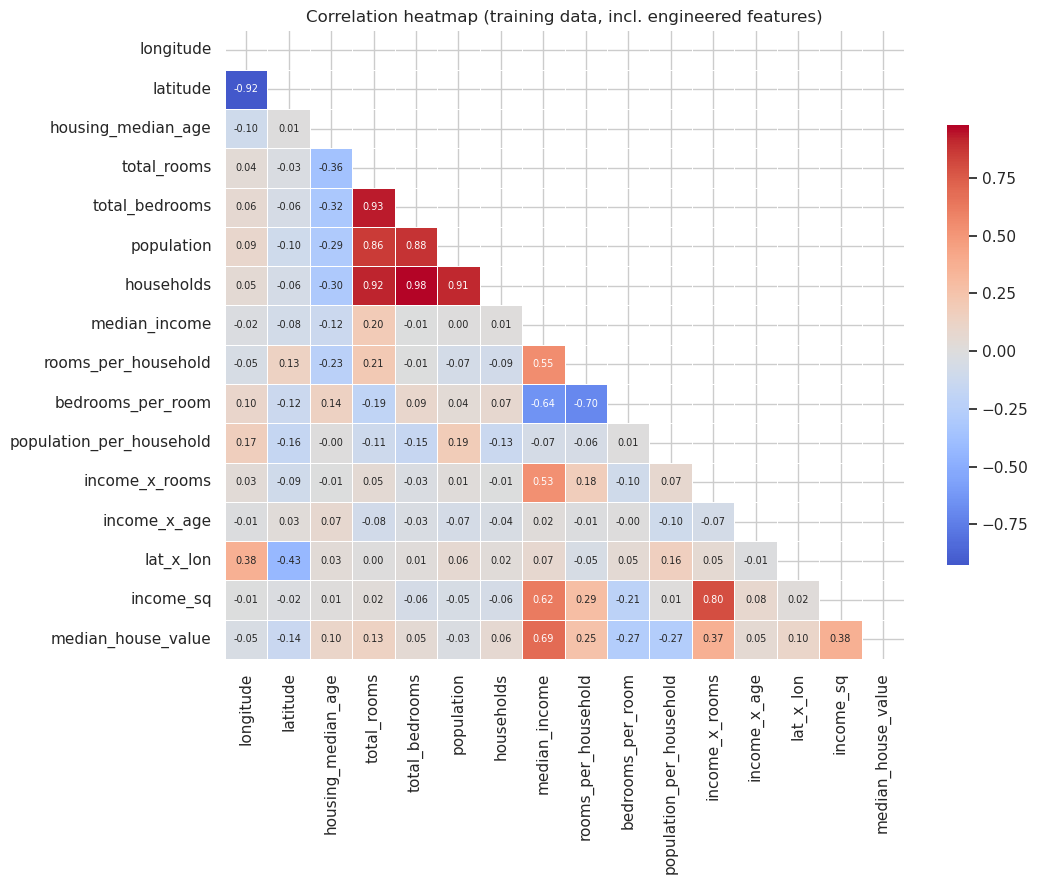

Correlation with target:
median_income               0.691
income_sq                   0.376
income_x_rooms              0.365
rooms_per_household         0.252
total_rooms                 0.134
housing_median_age          0.104
lat_x_lon                   0.103
households                  0.064
income_x_age                0.052
total_bedrooms              0.048
population                 -0.026
longitude                  -0.046
latitude                   -0.143
population_per_household   -0.270
bedrooms_per_room          -0.272
Name: median_house_value, dtype: float64


In [11]:
num_cols = X_train_fe.select_dtypes("number").columns.tolist()
corr = pd.concat([X_train_fe[num_cols], y_train], axis=1).corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.5, cbar_kws={"shrink": .7})
plt.title("Correlation heatmap (training data, incl. engineered features)")
plt.tight_layout(); plt.show()

print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

The block `total_rooms / total_bedrooms / population / households` is almost perfectly correlated — classic multicollinearity. Let's quantify it with the **Variance Inflation Factor** (VIF > 10 is a common red flag). VIF is computed directly with NumPy: regress each feature on all the others, `VIF = 1 / (1 − R²)`.

### 4.2 Variance Inflation Factor (VIF) — full feature set

In [12]:
def compute_vif(frame):
    Z = StandardScaler().fit_transform(frame)
    vifs = []
    for i in range(Z.shape[1]):
        others = np.delete(Z, i, axis=1)
        r2 = LinearRegression().fit(others, Z[:, i]).score(others, Z[:, i])
        vifs.append(1 / (1 - r2) if r2 < 1 else np.inf)
    return pd.Series(vifs, index=frame.columns).sort_values(ascending=False)

vif = compute_vif(X_train_fe[num_cols])
vif.round(1).to_frame("VIF")

,VIF
households,72.1
total_bedrooms,67.5
total_rooms,21.6
population,13.5
latitude,10.6
longitude,9.8
bedrooms_per_room,4.9
rooms_per_household,4.6
median_income,4.2
income_sq,3.7


VIFs are huge for the raw count columns (`total_rooms`, `total_bedrooms`, `population`, `households`) and for latitude/longitude. Note that the interaction terms are **mean-centered** in the feature engineer — without centering, `income_sq` and `lat_x_lon` have VIFs in the thousands because a product/square is almost a linear copy of its parents. We deal with the remaining collinearity in two complementary ways:

1. **Regularise** – Ridge shrinks correlated coefficients together; Lasso picks one and zeroes the others. This is the main approach and all three headline models use the **full** feature set.
2. **Remove redundancy (diagnostic)** – we also try dropping the raw `total_*` / `population` counts that the ratio features already summarise, to check how much information that costs.

### 4.3 VIF after dropping redundant raw counts

In [13]:
DROP_COLLINEAR = ["total_rooms", "total_bedrooms", "population", "households"]
reduced_cols = [c for c in num_cols if c not in DROP_COLLINEAR]

vif_reduced = compute_vif(X_train_fe[reduced_cols])
print("Max VIF full feature set   :", round(vif.max(), 1))
print("Max VIF after dropping raw counts:", round(vif_reduced.max(), 1))
vif_reduced.round(1).to_frame("VIF (reduced set)")

Max VIF full feature set   : 72.1
Max VIF after dropping raw counts: 10.6


,VIF (reduced set)
latitude,10.6
longitude,9.7
median_income,4.1
income_sq,3.6
income_x_rooms,3.2
bedrooms_per_room,3.0
rooms_per_household,2.3
lat_x_lon,1.2
housing_median_age,1.2
population_per_household,1.1


Dropping the raw counts removes the worst VIFs; only `latitude`/`longitude` stay near 10 because the California coast runs diagonally. They are very informative, so we keep them in every model.

## 5. Preprocessing pipeline
* Numeric: median impute → **StandardScaler** (required so the L1/L2 penalty treats every feature equally)
* Categorical `ocean_proximity`: most-frequent impute → **one-hot** encode

### 5.1 Build the preprocessing and modelling pipeline

In [14]:
cat_cols = ["ocean_proximity"]
num_reduced = reduced_cols  # engineered + remaining raw numeric columns

def make_preprocessor(numeric_columns):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_columns),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first"))]), cat_cols),
    ])

def make_pipeline(model, numeric_columns):
    return Pipeline([
        ("fe", HousingFeatureEngineer()),
        ("prep", make_preprocessor(numeric_columns)),
        ("model", model),
    ])

## 6. Fit models
* **OLS** – baseline, all features
* **Ridge** – all features, `alpha` tuned with 5-fold `GridSearchCV`
* **Lasso** – all features, `alpha` tuned with 5-fold `GridSearchCV`
* **OLS (reduced)** – reference only: OLS after dropping the redundant raw counts

Scoring for the search is negative RMSE.

### 6.1 Fit OLS, Ridge and Lasso (GridSearchCV for alpha)

In [15]:
alphas = np.logspace(-2, 3.5, 25)
cv_kwargs = dict(cv=5, scoring="neg_root_mean_squared_error", return_train_score=True)

# --- OLS ---------------------------------------------------------------
ols_all = make_pipeline(LinearRegression(), num_cols).fit(X_train, y_train)
ols_red = make_pipeline(LinearRegression(), num_reduced).fit(X_train, y_train)   # reference

# --- Ridge (L2) --------------------------------------------------------
ridge_gs = GridSearchCV(make_pipeline(Ridge(random_state=RANDOM_STATE), num_cols),
                        {"model__alpha": alphas}, **cv_kwargs).fit(X_train, y_train)

# --- Lasso (L1) --------------------------------------------------------
lasso_gs = GridSearchCV(make_pipeline(Lasso(max_iter=50000, random_state=RANDOM_STATE), num_cols),
                        {"model__alpha": alphas}, **cv_kwargs).fit(X_train, y_train)

print(f"Best Ridge alpha: {ridge_gs.best_params_['model__alpha']:.4g}   (CV RMSE {-ridge_gs.best_score_:,.0f})")
print(f"Best Lasso alpha: {lasso_gs.best_params_['model__alpha']:.4g}   (CV RMSE {-lasso_gs.best_score_:,.0f})")

Best Ridge alpha: 1.155   (CV RMSE 64,957)
Best Lasso alpha: 0.6813   (CV RMSE 64,958)


### 6.2 Alpha vs RMSE curves

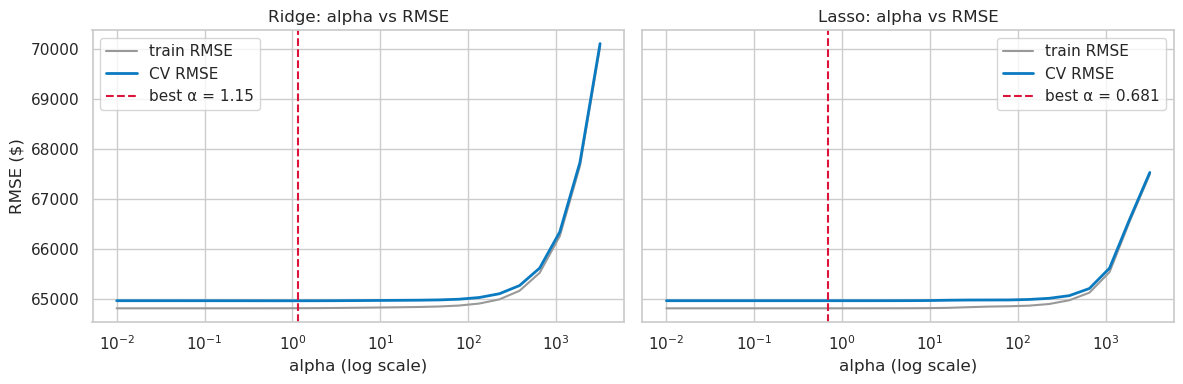

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, gs, name in zip(axes, [ridge_gs, lasso_gs], ["Ridge", "Lasso"]):
    a = gs.cv_results_["param_model__alpha"].astype(float)
    ax.semilogx(a, -gs.cv_results_["mean_train_score"], label="train RMSE", color="#999")
    ax.semilogx(a, -gs.cv_results_["mean_test_score"],  label="CV RMSE",   color="#0b7bc1", lw=2)
    ax.axvline(gs.best_params_["model__alpha"], ls="--", color="crimson",
               label=f"best α = {gs.best_params_['model__alpha']:.3g}")
    ax.set_title(f"{name}: alpha vs RMSE"); ax.set_xlabel("alpha (log scale)"); ax.legend()
axes[0].set_ylabel("RMSE ($)")
plt.tight_layout(); plt.show()

## 7. Evaluate on the held-out test set

### 7.1 Test-set metrics table

In [19]:
models = {
    "OLS":                ols_all,
    "Ridge (L2)":         ridge_gs.best_estimator_,
    "Lasso (L1)":         lasso_gs.best_estimator_,
    "OLS (reduced) ref.": ols_red,
}
MAIN = ["OLS", "Ridge (L2)", "Lasso (L1)"]

def evaluate(est, X_, y_):
    pred = est.predict(X_)
    return {"RMSE": np.sqrt(mean_squared_error(y_, pred)),
            "MAE":  mean_absolute_error(y_, pred),
            "R²":   r2_score(y_, pred)}

rows = {}
for name, est in models.items():
    tr, te = evaluate(est, X_train, y_train), evaluate(est, X_test, y_test)
    rows[name] = {"Train RMSE": tr["RMSE"], "Test RMSE": te["RMSE"],
                  "Test MAE": te["MAE"], "Train R²": tr["R²"], "Test R²": te["R²"]}

results = pd.DataFrame(rows).T
results.round({"Train RMSE": 0, "Test RMSE": 0, "Test MAE": 0, "Train R²": 4, "Test R²": 4})

,Train RMSE,Test RMSE,Test MAE,Train R²,Test R²
OLS,64815.0,67418.0,49044.0,0.6857,0.6531
Ridge (L2),64817.0,67427.0,49052.0,0.6857,0.6531
Lasso (L1),64815.0,67420.0,49046.0,0.6857,0.6531
OLS (reduced) ref.,64988.0,67767.0,49287.0,0.6841,0.6495


### 7.2 Metrics bar charts

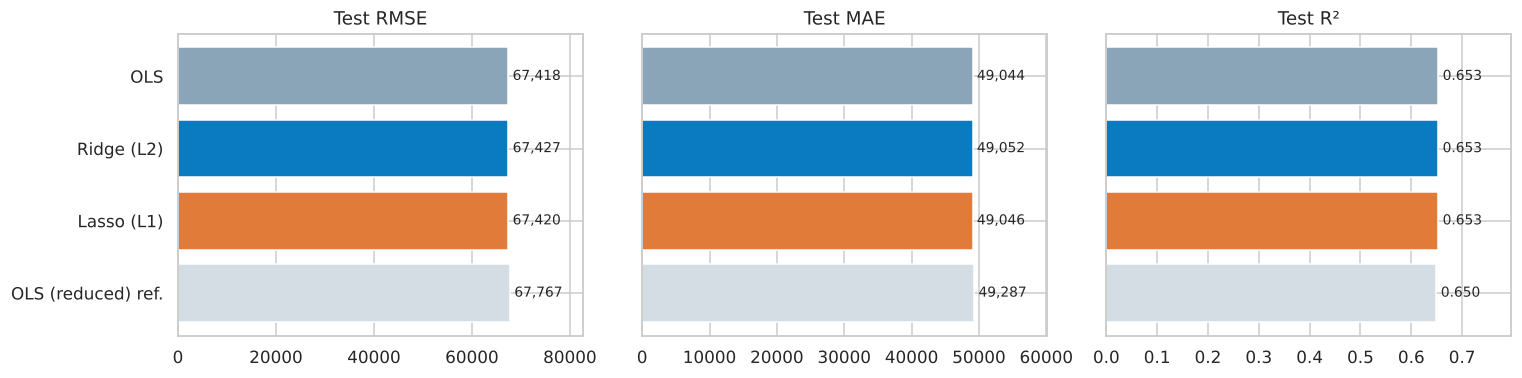

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
colors = ["#8aa4b8", "#0b7bc1", "#e07b39", "#d5dde4"]
for ax, metric in zip(axes, ["Test RMSE", "Test MAE", "Test R²"]):
    vals = results[metric]
    ax.barh(vals.index, vals.values, color=colors)
    ax.invert_yaxis(); ax.set_title(metric)
    for i, v in enumerate(vals.values):
        ax.text(v, i, f" {v:,.0f}" if "R²" not in metric else f" {v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0, vals.max() * 1.22)
for ax in axes[1:]: ax.set_yticklabels([])
plt.tight_layout(); plt.show()

## 8. Predicted vs actual

### 8.1 Predicted vs actual plots

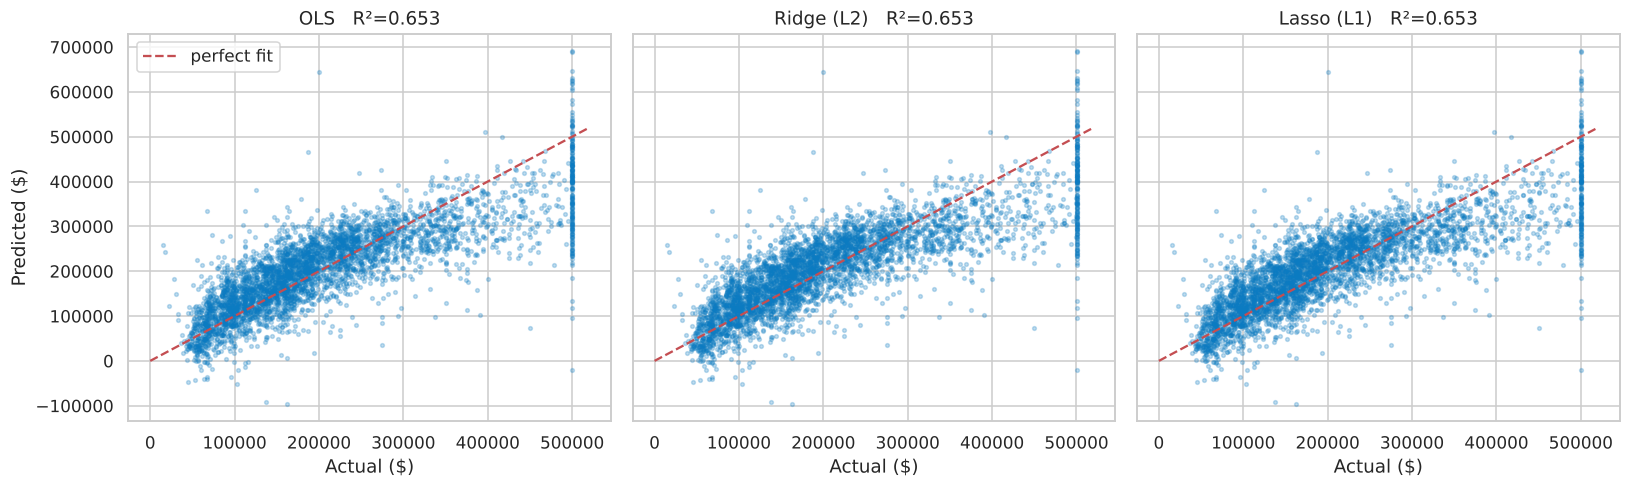

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, MAIN):
    pred = models[name].predict(X_test)
    ax.scatter(y_test, pred, s=6, alpha=.25, color="#0b7bc1")
    lims = [0, 520000]
    ax.plot(lims, lims, "r--", lw=1.5, label="perfect fit")
    ax.set_title(f"{name}   R²={r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual ($)")
axes[0].set_ylabel("Predicted ($)"); axes[0].legend()
plt.tight_layout(); plt.show()

## 9. Residual analysis

### 9.1 Residual distributions and residuals vs predicted

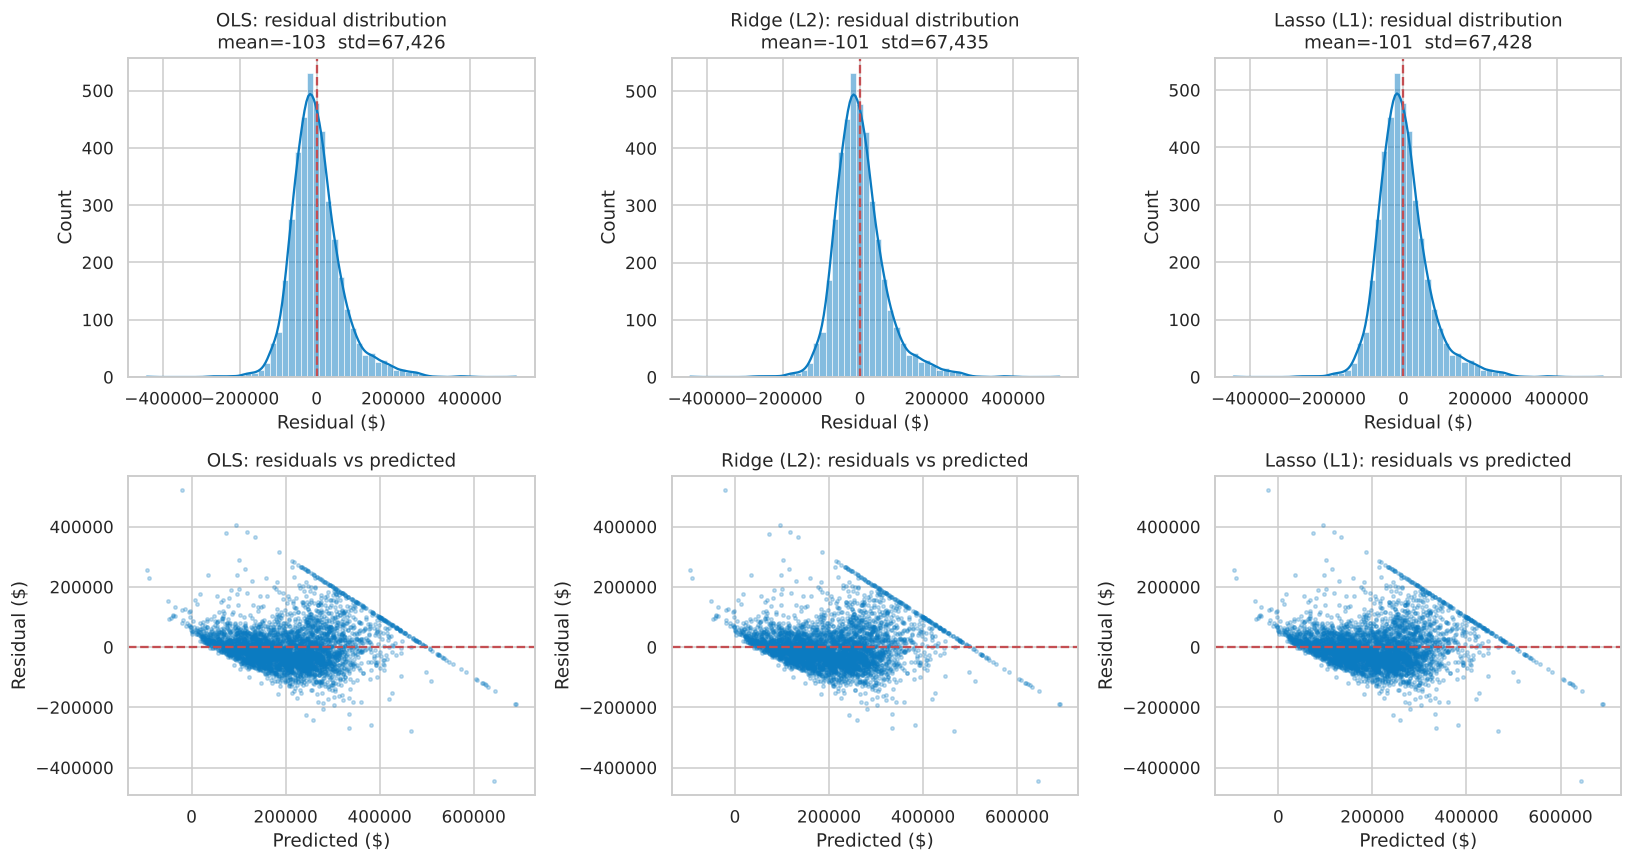

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, name in enumerate(MAIN):
    pred = models[name].predict(X_test)
    resid = y_test - pred

    sns.histplot(resid, bins=60, kde=True, ax=axes[0, j], color="#0b7bc1")
    axes[0, j].axvline(0, color="r", ls="--")
    axes[0, j].set_title(f"{name}: residual distribution\nmean={resid.mean():,.0f}  std={resid.std():,.0f}")
    axes[0, j].set_xlabel("Residual ($)")

    axes[1, j].scatter(pred, resid, s=5, alpha=.25, color="#0b7bc1")
    axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set_xlabel("Predicted ($)"); axes[1, j].set_ylabel("Residual ($)")
    axes[1, j].set_title(f"{name}: residuals vs predicted")
plt.tight_layout(); plt.show()

**Reading the residual plots**
* Residuals are centred on ≈ 0 and roughly bell-shaped, with a **longer right tail** — the models under-predict the most expensive block groups.
* The sharp **diagonal line** in *residuals vs predicted* is the **$500,001 cap**: every capped row has actual = 500,001, so residual = 500,001 − prediction falls exactly on a straight line. The vertical stripe at the right of the predicted-vs-actual plot is the same thing.
* Residuals trend downward as the prediction rises (cheap areas are over-predicted, expensive ones under-predicted) — a sign of non-linearity that a plain linear model can't capture.
* The three models are indistinguishable by eye, which matches the metrics table.

## 10. Coefficients — what did regularisation do?

### 10.1 Coefficient comparison

Features zeroed out by Lasso: none
,Non-zero Lasso coefficients : 19 of 19
,

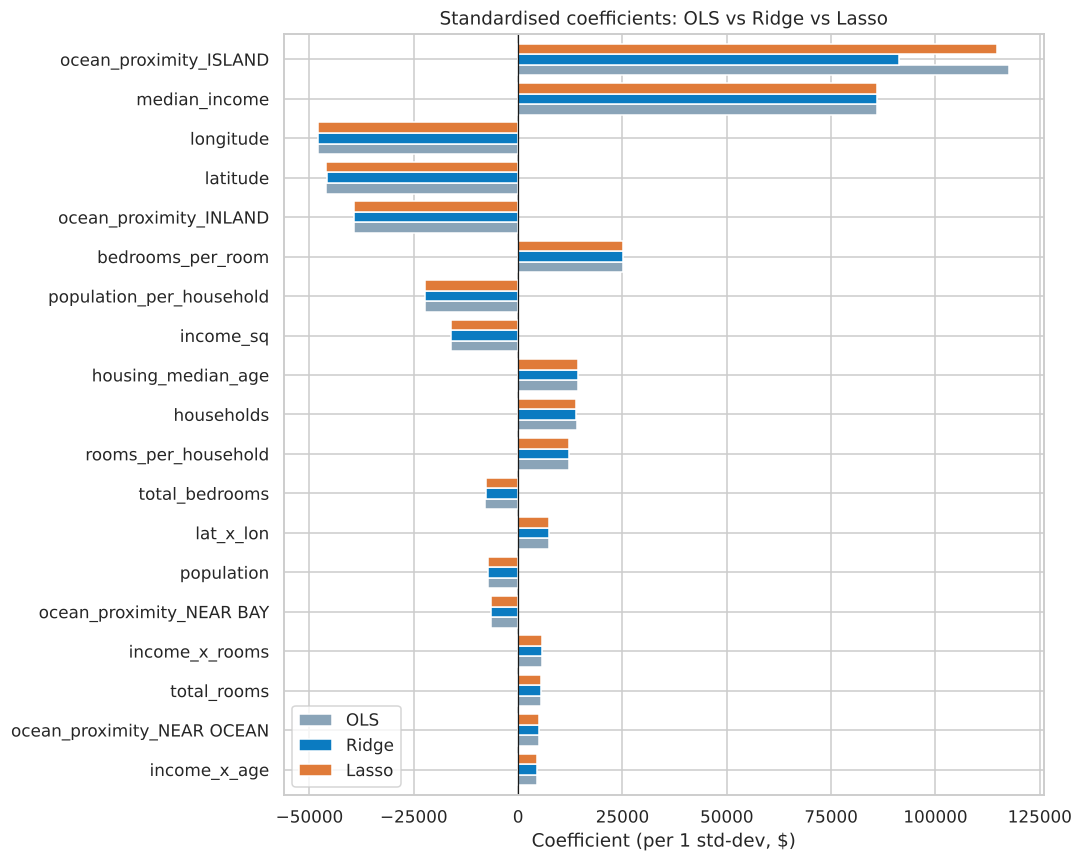

,OLS,Ridge,Lasso
longitude,-47883,-47837,-47868
latitude,-45951,-45908,-45937
housing_median_age,14444,14447,14443
total_rooms,5532,5522,5502
total_bedrooms,-7896,-7758,-7782
population,-7140,-7111,-7114
households,13995,13839,13885
median_income,86088,86071,86091
rooms_per_household,12165,12146,12146
bedrooms_per_room,25089,25067,25069


In [20]:
def get_coefs(est):
    prep = est.named_steps["prep"]
    names = prep.get_feature_names_out()
    names = [n.split("__", 1)[1] for n in names]
    return pd.Series(est.named_steps["model"].coef_, index=names)

coef_df = pd.DataFrame({
    "OLS":   get_coefs(ols_all),
    "Ridge": get_coefs(models["Ridge (L2)"]),
    "Lasso": get_coefs(models["Lasso (L1)"]),
})
print("Features zeroed out by Lasso:", list(coef_df.index[coef_df["Lasso"] == 0]) or "none")
print("Non-zero Lasso coefficients :", int((coef_df['Lasso'] != 0).sum()), "of", len(coef_df))

order = coef_df["OLS"].abs().sort_values().index
coef_df.loc[order].plot.barh(figsize=(10, 8), width=.8, color=["#8aa4b8", "#0b7bc1", "#e07b39"])
plt.title("Standardised coefficients: OLS vs Ridge vs Lasso")
plt.axvline(0, color="k", lw=.8); plt.xlabel("Coefficient (per 1 std-dev, $)")
plt.tight_layout(); plt.show()

coef_df.round(0).astype(int)

### Lasso regularisation path
At the CV-optimal `alpha` the penalty is tiny, so Lasso keeps almost everything. Here is how coefficients shrink as `alpha` grows — this is where Lasso's feature selection becomes visible.

### 10.2 Lasso regularisation path

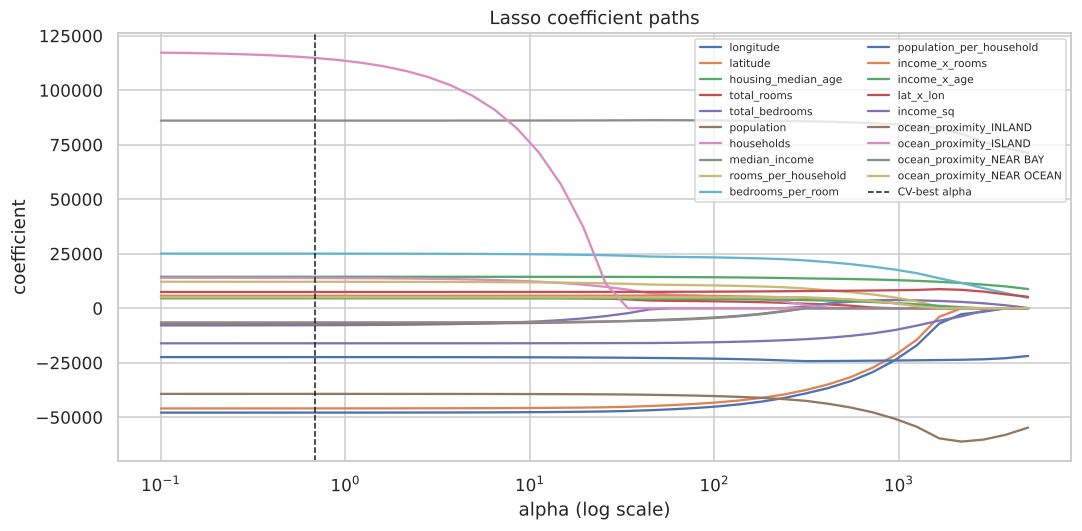

,alpha where coef -> 0
ocean_proximity_ISLAND,33.9
total_bedrooms,59.1
ocean_proximity_NEAR BAY,312.5
population,312.5
households,544.4
total_rooms,948.3
income_x_rooms,1651.8
ocean_proximity_NEAR OCEAN,1651.8
latitude,2180.0
rooms_per_household,2180.0


In [21]:
prep = Pipeline([("fe", HousingFeatureEngineer()), ("prep", make_preprocessor(num_cols))]).fit(X_train)
Xt = prep.transform(X_train)
feat = [n.split("__", 1)[1] for n in prep.named_steps["prep"].get_feature_names_out()]

path_alphas = np.logspace(-1, 3.7, 40)
paths = np.array([Lasso(alpha=a, max_iter=50000).fit(Xt, y_train).coef_ for a in path_alphas])

plt.figure(figsize=(10, 5))
for j, f in enumerate(feat):
    plt.semilogx(path_alphas, paths[:, j], label=f)
plt.axvline(lasso_gs.best_params_["model__alpha"], color="k", ls="--", lw=1, label="CV-best alpha")
plt.xlabel("alpha (log scale)"); plt.ylabel("coefficient")
plt.title("Lasso coefficient paths"); plt.legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

# alpha at which each feature first hits exactly zero
zero_at = {f: (path_alphas[np.argmax(paths[:, j] == 0)] if (paths[:, j] == 0).any() else np.nan)
           for j, f in enumerate(feat)}
pd.Series(zero_at, name="alpha where coef -> 0").sort_values().round(1).to_frame()

## 11. Conclusion

### 11.1 Final model comparison

In [22]:
main = results.loc[MAIN]
best = main["Test RMSE"].idxmin()
print(f"Best of OLS / Ridge / Lasso on test RMSE: {best}")
print(main[["Test RMSE", "Test MAE", "Test R²"]].round(4).to_string())
print()
print("Ridge vs OLS test RMSE difference: $%.1f" % (main.loc['Ridge (L2)', 'Test RMSE'] - main.loc['OLS', 'Test RMSE']))
print("Lasso vs OLS test RMSE difference: $%.1f" % (main.loc['Lasso (L1)', 'Test RMSE'] - main.loc['OLS', 'Test RMSE']))

Best of OLS / Ridge / Lasso on test RMSE: OLS
,             Test RMSE    Test MAE  Test R²
,OLS         67417.7708  49044.4643   0.6531
,Ridge (L2)  67427.3569  49052.4247   0.6531
,Lasso (L1)  67419.6543  49045.8420   0.6531
,
,Ridge vs OLS test RMSE difference: $9.6
,Lasso vs OLS test RMSE difference: $1.9
,

### Summary
* **Imputation & features:** 207 missing `total_bedrooms` values were median-imputed (statistics from the training split only). Ratio/interaction features (`bedrooms_per_room`, `rooms_per_household`, `income_x_rooms`, …) were added, with ratios winsorised and interactions mean-centered.
* **Multicollinearity:** raw `total_rooms` / `total_bedrooms` / `households` / `population` had VIF ≈ 20–70 and latitude/longitude ≈ 10; mean-centering removed the artificial collinearity of the interaction terms.
* **Model comparison:** OLS, Ridge and Lasso reach essentially **identical test performance (R² ≈ 0.65, RMSE ≈ $67.4k, MAE ≈ $49k)**. This is expected: with ~16k training rows and only 19 features there is little variance for regularisation to remove, so the best `alpha` found by `GridSearchCV` is small (≈ 1) and the penalty barely changes the coefficients. The same is true after dropping the redundant raw counts (OLS reduced, R² ≈ 0.65), which shows the multicollinearity inflates coefficient variance more than it hurts predictions.
* **What regularisation *did* do:** Ridge shrank the unstable coefficients (e.g. the 5-row `ISLAND` category: 118k → 91k) and the Lasso path shows the order in which features are dropped as `alpha` increases — a useful guide to importance. The tiny `ISLAND` category (5 rows) goes first, then the redundant counts (`total_bedrooms`, `population`, `households`, `total_rooms`), while `median_income`, `bedrooms_per_room`, `population_per_household` and `ocean_proximity_INLAND` survive even the strongest penalty tested. At the CV-optimal `alpha`, Lasso zeroes out no feature.
* **Limitations / next steps:** the $500k cap and the visible non-linearity limit any linear model. Natural improvements: model `log(median_house_value)`, drop or treat the capped rows, add `PolynomialFeatures` + `ElasticNet`, or try a tree ensemble (`GradientBoostingRegressor`), which typically reaches R² ≈ 0.80+ on this data.